# Project 2a: Forward Kinematics

[Eadweard Muybridge](https://en.wikipedia.org/wiki/Eadweard_Muybridge) was a photographer who studied the galloping motion of horses. He showed that during a full gallop, there is a point where all four hooves of a horse are off the ground. 

In this part of Project 2 you will choose joint trajectories that move a robot leg between the swing and stance phase, simulating walking in the body frame. This will lead up to you controlling the Spot robot - a walking quadruped from Boston Dynamics. 

This notebook needs to be run locally on VS Code. Create a virtual conda environment using the provided `environment.yml` file by running the following command and be sure to select it as the kernel.

`conda env create -f environment.yml`

`leg_plotter.py` is preconfigured for this notebook and will bring up a live interactive figure.

In [1]:
%matplotlib qt
import matplotlib.pyplot as plt
plt.ion()  # interactive mode on

import numpy as np
import gtsam
from leg_plotter import launch

An example of the live interactive figure is shown below. The joint angle plots are on the left and the foot trajectory plot is on the right.

<p align="center">
  <img src="example_trajectory.png" width="800">
</p>

GTSAM is used to fit a Fourier basis to the selected points on the $\theta_1(t)$ and $\theta_2(t)$ plots, generating the finer-resolution joint-space trajectory shown in blue. The plots are initialized with five seeded control points at $t=0,1,2,3,4$ (all zero angles) colored red, pink, yellow, green, and blue. Seeded points can only be dragged vertically (their time is fixed). You can still add extra points with mouse clicks and drag those freely. You must have at least 3 points on each joint-angle graph for a fitted trajectory to appear. You can delete points by selecting them and pressing backspace. The fitted trajectory live-updates as you edit points.

Once both joint angles have a fitted trajectory, the path of the foot (computed using closed-form forward kinematics) in Cartesian space is auto-plotted and live-adjusts with the joint-space trajectory. The hip is the black cross (default base height $y_0=3.4$), and the two leg links are shown in black. The task targets now use color and marker coding for accessibility: red circle at $t=0$, pink square at $t=1$, yellow triangle at $t=2$, green diamond at $t=3$, and blue plus-filled marker at $t=4$. Black arrows indicate direction, and intermediate one-second FK markers/ghost poses follow the same color sequence.

For a total of 10 points, generate a walking-like foot trajectory that follows this order: start at red ($t=0$), hit pink ($t=1$) then yellow ($t=2$) during swing, then pass through green ($t=3$) and blue ($t=4$) during stance near the ground line ($y=0$). The colored dots on the foot path show where your foot is at each of these times.

Your trajectory is graded automatically:
1. **Targets (5 points):** 1 point for each Muybridge target your foot is within 10 cm of at that target's time.
2. **Ground (5 points):** each separate time your foot goes below the ground line costs 1 point per started second underground (a 0.3 s dip costs 1 point, a 1.2 s dip costs 2). Dips shallower than 1 cm are ignored.

Run the cell below to launch the interactive figure.

In [2]:
plotter = launch()

### Check your score

Run the cell below at any time to score your current trajectory. It uses the same scoring as the Gradescope autograder, so you can keep adjusting your points in the figure and run it again.

In [6]:
from trajectory_check import check

check(plotter)

[1/1] Target red at t = 0 s
    Foot at (0.494, 0.083) m, 8.4 cm from the target (0.500, 0.000) m. Tolerance: 10 cm.
[1/1] Target pink at t = 1 s
    Foot at (2.507, 0.716) m, 1.7 cm from the target (2.500, 0.700) m. Tolerance: 10 cm.
[1/1] Target yellow at t = 2 s
    Foot at (4.493, 0.019) m, 2.0 cm from the target (4.500, 0.000) m. Tolerance: 10 cm.
[1/1] Target green at t = 3 s
    Foot at (3.215, 0.085) m, 9.8 cm from the target (3.167, 0.000) m. Tolerance: 10 cm.
[1/1] Target blue at t = 4 s
    Foot at (1.875, 0.067) m, 7.9 cm from the target (1.833, 0.000) m. Tolerance: 10 cm.
[5/5] Foot stays above ground
    The foot stays above the ground line (lowest point y = -0.003 m).
Trajectory score: 10 / 10


### Save your final trajectory

When your trajectory is final, run the cell below. It shows a picture of your figure and prints the numeric values of your chosen joint-space points. **The autograder grades the points printed here, not the live figure**, and the picture lets the instructor see your trajectory. If you move, add or delete any points afterwards, run this cell again. NaN values appear if the number of points is not the same for each joint angle.

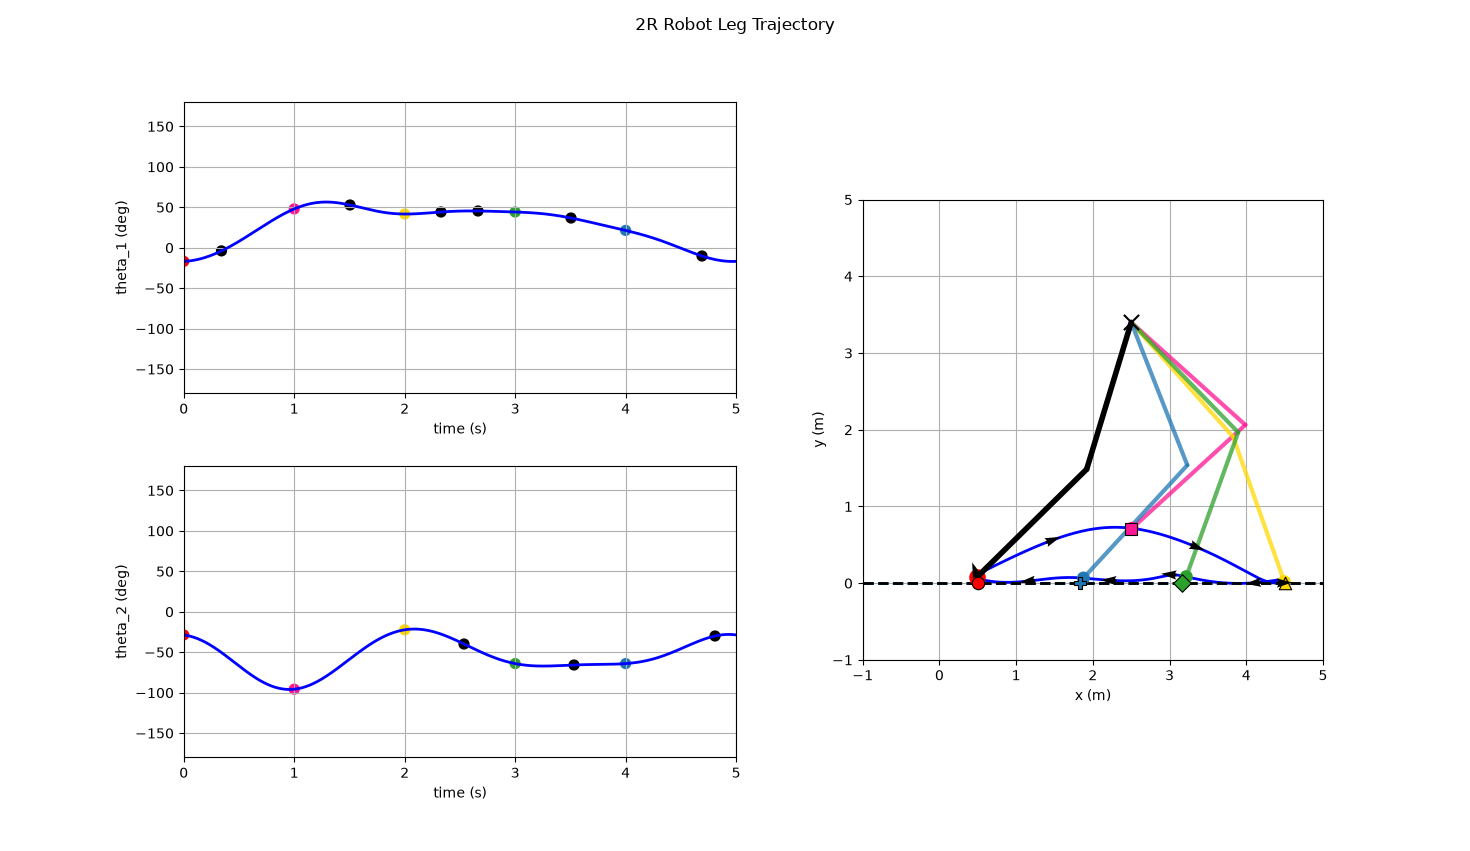

Point		time_1		theta_1		time_2		theta_2
--------------------------------------------------------------------------------
1		0.00		-16.86		0.00		-28.61
2		1.00		47.99		1.00		-95.70
3		2.00		41.66		2.00		-22.28
4		3.00		44.20		3.00		-64.06
5		4.00		21.41		4.00		-64.06
6		0.34		-3.91		4.81		-29.95
7		1.50		52.83		3.53		-65.79
8		2.33		44.17		2.54		-39.84
9		4.69		-10.22		nan		nan
10		3.51		36.76		nan		nan
11		2.66		45.41		nan		nan


In [7]:
import io
from IPython.display import Image, display

# Picture of your final figure, saved in this notebook
buffer = io.BytesIO()
plotter.fig.savefig(buffer, format="png", dpi=100)
display(Image(data=buffer.getvalue()))

# Your final points: the autograder grades this table
print("Point\t\ttime_1\t\ttheta_1\t\ttime_2\t\ttheta_2")
print("-" * 80)
i_max = max(len(plotter.theta1_clicks), len(plotter.theta2_clicks))
for i in range(i_max):
    if i < len(plotter.theta1_clicks):
        t1, theta1 = plotter.theta1_clicks[i]
    else:
        t1, theta1 = np.nan, np.nan
    if i < len(plotter.theta2_clicks):
        t2, theta2 = plotter.theta2_clicks[i]
    else:
        t2, theta2 = np.nan, np.nan
    print(f"{i + 1}\t\t{t1:.2f}\t\t{np.degrees(theta1):.2f}\t\t{t2:.2f}\t\t{np.degrees(theta2):.2f}")

Congratulations! You completed the forward kinematics portion of Project 2.

## Submission

This project is worth 10 points, all autograded from your table. Your figure must also be in the notebook.

1. When your trajectory is final, run the cell above that shows your figure and prints your points.
2. Save the notebook; the figure and the table are saved with it. Do this before closing VS Code or restarting the kernel, because your points exist only in the open figure.
3. Upload only `Project_2a_FK.ipynb` to Gradescope. The autograder grades the table and reports the same score as `check(plotter)`.